# 03 - Deneyler (E1-E3)

Ortak kod `common.py` dosyasından geliyor. E1 girdi türünü, E2 kayıp fonksiyonunu, E3 uçuş yüksekliğini (GSD) karşılaştırıyor. Model seçimi yalnızca doğrulama setiyle yapıldı.

## 1. Kurulum

In [7]:
!pip install -q segmentation-models-pytorch==0.5.0
from google.colab import drive
drive.mount('/content/drive')

import os, sys, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch

PROJE = '/content/drive/MyDrive/multispectral-weed-segmentation'   # common.py bu klasörde
sys.path.insert(0, PROJE)
import common as o

o.hazirla()
o.set_seed(o.SEED)

Hazır: 156 görüntü | split [104, 26, 26] | cihaz cuda


## 2. E1: girdi karşılaştırması

E0_rgb_3s: zaten var, atlanıyor


[E1_rgb_exg_3s] ep   1 | train 0.652 | val 44.379 | val mIoU 0.100 | en iyi 0.100 (ep 1) | 0.2 dk
[E1_rgb_exg_3s] ep  10 | train 0.098 | val 0.106 | val mIoU 0.676 | en iyi 0.676 (ep 10) | 1.5 dk
[E1_rgb_exg_3s] ep  20 | train 0.078 | val 0.091 | val mIoU 0.705 | en iyi 0.736 (ep 12) | 2.9 dk
[E1_rgb_exg_3s] ep  30 | train 0.065 | val 0.073 | val mIoU 0.760 | en iyi 0.761 (ep 29) | 4.2 dk
[E1_rgb_exg_3s] ep  40 | train 0.061 | val 0.069 | val mIoU 0.762 | en iyi 0.772 (ep 38) | 5.6 dk
[E1_rgb_exg_3s] ep  50 | train 0.058 | val 0.069 | val mIoU 0.775 | en iyi 0.783 (ep 44) | 6.9 dk
[E1_rgb_exg_3s] ep  60 | train 0.057 | val 0.067 | val mIoU 0.767 | en iyi 0.787 (ep 58) | 8.2 dk
[E1_rgb_exg_3s] ep  70 | train 0.054 | val 0.069 | val mIoU 0.758 | en iyi 0.790 (ep 69) | 9.5 dk
[E1_rgb_exg_3s] ep  80 | train 0.054 | val 0.063 | val mIoU 0.787 | en iyi 0.796 (ep 77) | 10.8 dk
[E1_rgb_exg_3s] ep  90 | train 0.054 | val 0.061 | val mIoU 0.792 | en iyi 0.796 (ep 77) | 12.1 dk
[E1_rgb_exg_3s] ep

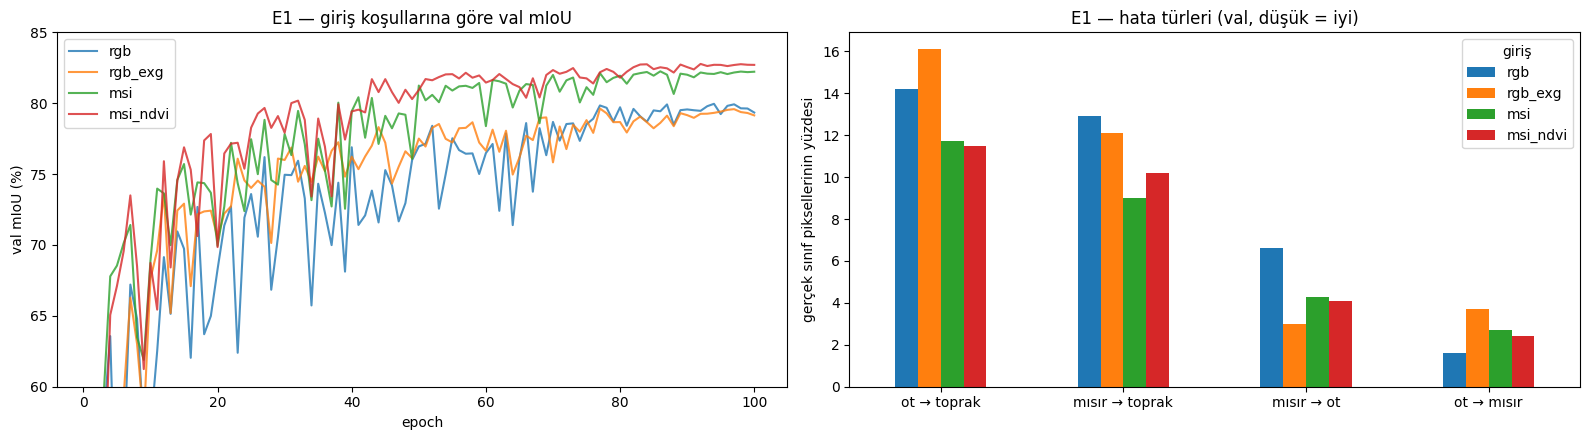

In [6]:
import os
KOSULAR = {'rgb':      'E0_rgb_3s',        # E0 ile aynı ayar -> yeniden koşmaya gerek yok (varsa)
           'rgb_exg':  'E1_rgb_exg_3s',
           'msi':      'E1_msi_3s',
           'msi_ndvi': 'E1_msi_ndvi_3s'}

# Eğitim: checkpoint ve özet dosyası olan koşuyu atla (kesinti olursa kaldığı yerden devam)
for kanal, deney in KOSULAR.items():
    if os.path.exists(f'{o.CKPT_DIR}/{deney}.pt') and os.path.exists(f'{o.RES_DIR}/{deney}_ozet.json'):
        print(f'{deney}: zaten var, atlanıyor')
        continue
    o.egit(deney, kanallar=kanal, n_sinif=3)

# Karşılaştırma: her koşunun en iyi (val) checkpoint'i ile val seti
satirlar, cm_hepsi, gecmis = [], {}, {}
for kanal, deney in KOSULAR.items():
    model = o.model_olustur(len(o.KANAL_SECIMI[kanal]), 3)
    model.load_state_dict(torch.load(f'{o.CKPT_DIR}/{deney}.pt'))
    cm, cm_t, _ = o.degerlendir(model, o.OtDataset(o.splits['val'], kanal, 3), 3)
    m = o.metrikler(cm)
    cmn = cm.cpu().numpy().astype(float); cmn /= cmn.sum(axis=1, keepdims=True)
    cm_hepsi[kanal] = cmn
    satirlar.append({'giriş': kanal,
                     'val mIoU': m['miou'], 'IoU arka plan': m['iou'][0], 'IoU mısır': m['iou'][1], 'IoU ot': m['iou'][2],
                     'ot recall': m['ot_recall'], 'mısır FP (ot sanılan)': m['misir_fp'],
                     'ot → toprak': cmn[2, 0], 'mısır → toprak': cmn[1, 0], 'mısır → ot': cmn[1, 2], 'ot → mısır': cmn[2, 1],
                     **{f'mIoU {d[5:]}': o.metrikler(cm_t[d])['miou'] for d in o.DATES}})
    gecmis[kanal] = pd.read_csv(f'{o.RES_DIR}/{deney}_gecmis.csv')
    del model; torch.cuda.empty_cache()

tablo = pd.DataFrame(satirlar).set_index('giriş').mul(100).round(1)
tablo.to_csv(f'{o.RES_DIR}/E1_karsilastirma_val.csv')
print(tablo.T.to_string())

# Görsel: (a) val mIoU eğrileri, (b) hata türleri - MSI hangi hatayı azaltıyor?
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
for kanal, df in gecmis.items():
    ax[0].plot(df.epoch, df.val_miou * 100, label=kanal, alpha=0.8)
ax[0].set_ylim(60, 85); ax[0].set_xlabel('epoch'); ax[0].set_ylabel('val mIoU (%)')
ax[0].set_title('E1 — giriş koşullarına göre val mIoU'); ax[0].legend()
hatalar = ['ot → toprak', 'mısır → toprak', 'mısır → ot', 'ot → mısır']
tablo[hatalar].T.plot.bar(ax=ax[1], rot=0)
ax[1].set_ylabel('gerçek sınıf piksellerinin yüzdesi')
ax[1].set_title('E1 — hata türleri (val, düşük = iyi)')
plt.tight_layout(); plt.savefig(f'{o.RES_DIR}/E1_karsilastirma.png', dpi=150); plt.show()

## 3. E2: nadir sınıflar ve kayıp fonksiyonu

           frekans %  ağırlık
arka plan     93.352    0.134
mısır          2.445    0.827
amaranth       2.715    0.785
darıcan        0.898    1.364
quickweed      0.181    3.036
diğer ot       0.409    2.022
[E2_msi_6s_ce] ep   1 | train 1.069 | val 3.918 | val mIoU 0.128 | en iyi 0.128 (ep 1) | 0.1 dk
[E2_msi_6s_ce] ep  10 | train 0.114 | val 0.127 | val mIoU 0.365 | en iyi 0.365 (ep 10) | 1.4 dk
[E2_msi_6s_ce] ep  20 | train 0.095 | val 0.096 | val mIoU 0.409 | en iyi 0.432 (ep 18) | 2.8 dk
[E2_msi_6s_ce] ep  30 | train 0.075 | val 0.085 | val mIoU 0.517 | en iyi 0.517 (ep 29) | 4.2 dk
[E2_msi_6s_ce] ep  40 | train 0.069 | val 0.081 | val mIoU 0.523 | en iyi 0.523 (ep 40) | 5.5 dk
[E2_msi_6s_ce] ep  50 | train 0.064 | val 0.073 | val mIoU 0.538 | en iyi 0.538 (ep 50) | 6.9 dk
[E2_msi_6s_ce] ep  60 | train 0.064 | val 0.085 | val mIoU 0.521 | en iyi 0.560 (ep 54) | 8.3 dk
[E2_msi_6s_ce] ep  70 | train 0.058 | val 0.075 | val mIoU 0.552 | en iyi 0.560 (ep 54) | 9.6 dk
[E2_msi_6s_ce] 

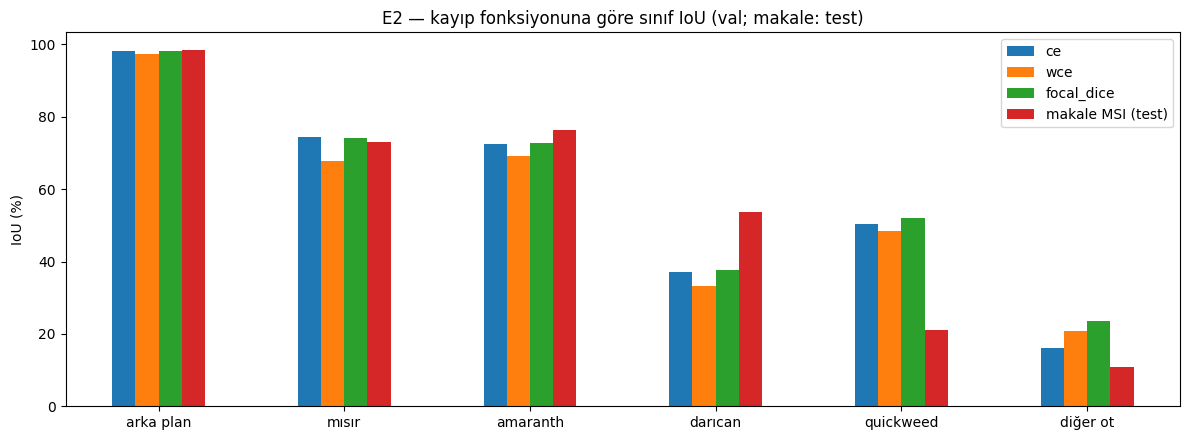

In [8]:
# Sınıf ağırlıkları: karekök medyan-frekans dengeleme (yalnız train)
piksel = np.zeros(6)
for ad in o.splits['train']:
    piksel += np.bincount(o.MASKE[ad].ravel(), minlength=6)
frekans = piksel / piksel.sum()
AGIRLIK = np.sqrt(np.median(frekans) / frekans)
print(pd.DataFrame({'frekans %': frekans * 100, 'ağırlık': AGIRLIK}, index=o.SINIFLAR).round(3).to_string())

# Eğitim (kayıplar common.py içinde), biten koşu atlanır
KOSULAR_E2 = {'E2_msi_6s_ce':         dict(kayip='ce',         agirlik=None),
              'E2_msi_6s_wce':        dict(kayip='ce',         agirlik=AGIRLIK.tolist()),
              'E2_msi_6s_focal_dice': dict(kayip='focal_dice', agirlik=None)}
for deney, ayar in KOSULAR_E2.items():
    if os.path.exists(f'{o.CKPT_DIR}/{deney}.pt') and os.path.exists(f'{o.RES_DIR}/{deney}_ozet.json'):
        print(f'{deney}: zaten var, atlanıyor'); continue
    o.egit(deney, kanallar='msi', n_sinif=6, **ayar)

# Karşılaştırma (val, en iyi checkpoint) + makale (6 sınıf MSI, TEST)
MAKALE = [98.37, 73.03, 76.17, 53.55, 21.11, 10.86]
satir, cm_e2 = {}, {}
for deney in KOSULAR_E2:
    model = o.model_olustur(5, 6)
    model.load_state_dict(torch.load(f'{o.CKPT_DIR}/{deney}.pt'))
    cm, _, _ = o.degerlendir(model, o.OtDataset(o.splits['val'], 'msi', 6), 6)
    m = o.metrikler(cm)
    cmn = cm.cpu().numpy().astype(float); cmn /= cmn.sum(axis=1, keepdims=True)
    cm_e2[deney] = cmn
    satir[deney.replace('E2_msi_6s_', '')] = list(m['iou'] * 100) + [m['miou'] * 100, m['ot_recall'] * 100,
                                                    m['misir_fp'] * 100, cmn[4, 2] * 100, cmn[5, 0] * 100]
    del model; torch.cuda.empty_cache()
satir['makale MSI (test)'] = MAKALE + [55.52, np.nan, np.nan, 28.0, np.nan]
tablo_e2 = pd.DataFrame(satir, index=[f'IoU {s}' for s in o.SINIFLAR] +
                        ['mIoU', 'ot recall (tüm otlar)', 'mısır → ot', 'quickweed → amaranth', 'diğer ot → toprak']).round(1)
tablo_e2.to_csv(f'{o.RES_DIR}/E2_karsilastirma_val.csv')
print(tablo_e2.to_string())

# Görsel: sınıf bazında IoU (koşullar yan yana)
fig, ax = plt.subplots(figsize=(12, 4.5))
tablo_e2.iloc[:6].plot.bar(ax=ax, rot=0)
ax.set_xticklabels(o.SINIFLAR); ax.set_ylabel('IoU (%)')
ax.set_title('E2 — kayıp fonksiyonuna göre sınıf IoU (val; makale: test)')
plt.tight_layout(); plt.savefig(f'{o.RES_DIR}/E2_karsilastirma.png', dpi=150); plt.show()

## 4. E3: GSD benzetimi

[E3_rgb_3s_gsd5] ep   1 | train 0.667 | val 4.018 | val mIoU 0.261 | en iyi 0.261 (ep 1) | 0.1 dk
[E3_rgb_3s_gsd5] ep  10 | train 0.098 | val 0.119 | val mIoU 0.586 | en iyi 0.654 (ep 9) | 1.3 dk
[E3_rgb_3s_gsd5] ep  20 | train 0.080 | val 0.092 | val mIoU 0.676 | en iyi 0.720 (ep 14) | 2.5 dk
[E3_rgb_3s_gsd5] ep  30 | train 0.071 | val 0.079 | val mIoU 0.721 | en iyi 0.756 (ep 25) | 3.8 dk
[E3_rgb_3s_gsd5] ep  40 | train 0.063 | val 0.072 | val mIoU 0.750 | en iyi 0.760 (ep 37) | 5.0 dk
[E3_rgb_3s_gsd5] ep  50 | train 0.059 | val 0.067 | val mIoU 0.772 | en iyi 0.772 (ep 50) | 6.3 dk
[E3_rgb_3s_gsd5] ep  60 | train 0.058 | val 0.070 | val mIoU 0.738 | en iyi 0.779 (ep 57) | 7.6 dk
[E3_rgb_3s_gsd5] ep  70 | train 0.055 | val 0.068 | val mIoU 0.763 | en iyi 0.785 (ep 69) | 8.9 dk
[E3_rgb_3s_gsd5] ep  80 | train 0.054 | val 0.061 | val mIoU 0.790 | en iyi 0.794 (ep 77) | 10.2 dk
[E3_rgb_3s_gsd5] ep  90 | train 0.054 | val 0.060 | val mIoU 0.794 | en iyi 0.795 (ep 87) | 11.4 dk
[E3_rgb_3s

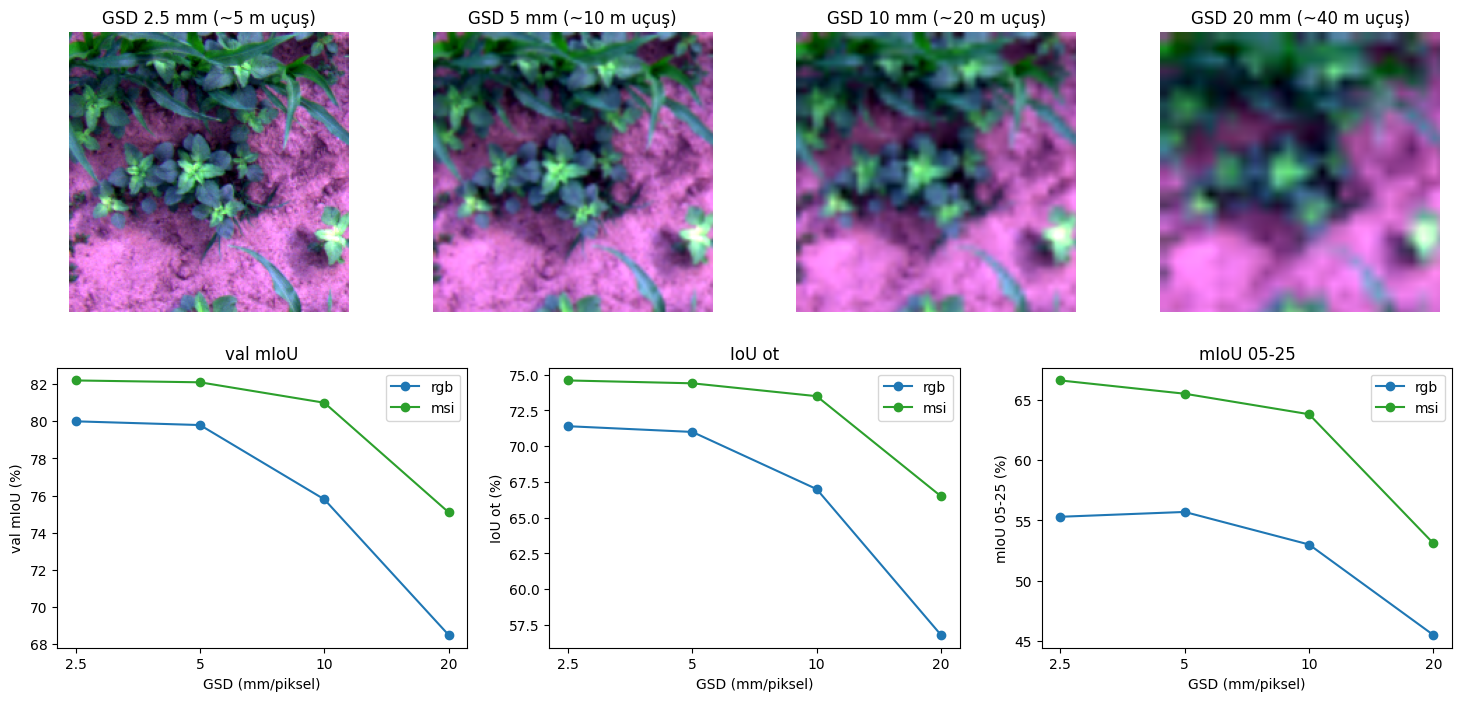

In [9]:
HAM_ORJ = dict(o.HAM)                        # orijinal (2,5 mm) görüntülerin yedeği
GSD = {5: 2, 10: 4, 20: 8}                   # GSD (mm) -> blok boyutu f
ESKI = {('rgb', 2.5): 'E0_rgb_3s', ('msi', 2.5): 'E1_msi_3s'}   # 2,5 mm sonuçları hazır

def val_ozet(deney, kanal):
    model = o.model_olustur(len(o.KANAL_SECIMI[kanal]), 3)
    model.load_state_dict(torch.load(f'{o.CKPT_DIR}/{deney}.pt'))
    cm, cm_t, _ = o.degerlendir(model, o.OtDataset(o.splits['val'], kanal, 3), 3)
    m = o.metrikler(cm)
    del model; torch.cuda.empty_cache()
    return {'val mIoU': m['miou'], 'IoU mısır': m['iou'][1], 'IoU ot': m['iou'][2],
            'ot recall': m['ot_recall'], 'mısır FP': m['misir_fp'],
            'mIoU 05-25': o.metrikler(cm_t['2023-05-25'])['miou'], 'mIoU 06-15': o.metrikler(cm_t['2023-06-15'])['miou']}

satirlar = []
# 2,5 mm: orijinal veriyle mevcut modeller
for (kanal, g), deney in ESKI.items():
    satirlar.append({'giriş': kanal, 'GSD (mm)': g, **val_ozet(deney, kanal)})

# 5 / 10 / 20 mm: görüntüleri boz -> eğit -> değerlendir
try:
    for g, f in GSD.items():
        for ad in HAM_ORJ:
            o.HAM[ad] = o.gsd_boz(HAM_ORJ[ad], f)          # Dataset artık bozulmuş görüntüyü okur
        for kanal in ['rgb', 'msi']:
            deney = f'E3_{kanal}_3s_gsd{g}'
            if not (os.path.exists(f'{o.CKPT_DIR}/{deney}.pt') and os.path.exists(f'{o.RES_DIR}/{deney}_ozet.json')):
                o.egit(deney, kanallar=kanal, n_sinif=3)
            else:
                print(f'{deney}: zaten var, atlanıyor')
            satirlar.append({'giriş': kanal, 'GSD (mm)': g, **val_ozet(deney, kanal)})
finally:
    o.HAM.update(HAM_ORJ)                                 # hata olsa bile orijinal görüntüleri geri koy

tablo_e3 = pd.DataFrame(satirlar)
tablo_e3.iloc[:, 2:] *= 100
tablo_e3 = tablo_e3.round(1).sort_values(['giriş', 'GSD (mm)'])
tablo_e3.to_csv(f'{o.RES_DIR}/E3_gsd_val.csv', index=False)
print(tablo_e3.to_string(index=False))

# Görsel: (a) aynı bölge 4 GSD'de, (b) mIoU ve ot IoU - GSD'ye göre
ad = o.splits['val'][0]
fig = plt.figure(figsize=(18, 8))
for i, (g, f) in enumerate([(2.5, 1)] + list(GSD.items())):
    x = HAM_ORJ[ad] if f == 1 else o.gsd_boz(HAM_ORJ[ad], f)
    rgb = np.stack([x[2], x[1], x[0]], -1)[:200, :200].astype(np.float32) / 65535   # 200×200 kırpıntı = 50 cm × 50 cm
    rgb = np.clip((rgb - np.percentile(rgb, 1)) / (np.percentile(rgb, 99) - np.percentile(rgb, 1)), 0, 1)
    ax = fig.add_subplot(2, 4, i + 1); ax.imshow(rgb); ax.axis('off')
    ax.set_title(f'GSD {g} mm (~{g * 2:.0f} m uçuş)')
for j, metrik in enumerate(['val mIoU', 'IoU ot', 'mIoU 05-25']):
    ax = fig.add_subplot(2, 3, 4 + j)
    for kanal, r in [('rgb', 'tab:blue'), ('msi', 'tab:green')]:
        d = tablo_e3[tablo_e3['giriş'] == kanal]
        ax.plot(d['GSD (mm)'], d[metrik], 'o-', color=r, label=kanal)
    ax.set_xscale('log', base=2); ax.set_xticks([2.5, 5, 10, 20], ['2.5', '5', '10', '20'])
    ax.set_xlabel('GSD (mm/piksel)'); ax.set_ylabel(f'{metrik} (%)'); ax.set_title(metrik); ax.legend()
plt.tight_layout(); plt.savefig(f'{o.RES_DIR}/E3_gsd.png', dpi=150); plt.show()